# Lab 6: "Field Trial" Test the Voice Emergency Stop on the Factory Floor

**Name:** Tanmay Gautam &nbsp;|&nbsp; **Register No.:** 2548559 &nbsp;|&nbsp; **Course:** TinyML

---

## Lab question

**Aim**

To deploy the int8 "stop" model from Lab 5 (trained on the Google Speech Commands dataset) and test it with recorded and live audio using streaming inference.

**Objectives**

1. Run int8 TFLite inference with the same MFCC front-end as in training.
2. Test the model with dataset clips, recorded audio and live microphone audio.
3. Implement streaming inference with a sliding window, smoothing, a threshold and a refractory period.
4. Measure misses, false alarms, model size and inference time.

**The problem**

Your Lab 5 model impressed the manager. Now comes the field trial. The safety officer will not accept test-set accuracy. She says: "Clean recordings from a dataset are not my factory. Show me it works with our workers' voices, from a distance, with the machine running. And it must listen all the time; nobody will press a button before shouting stop."

Your job: turn the model into a working voice emergency stop system in Google Colab. Every time "stop" is detected, the screen must show "🛑 BELT STOPPED". Every other word and every machine sound must be ignored.

**Your tasks**

1. **Install the brain (load the model).** Load kws_int8.tflite and the MFCC settings from kws_config.json (16 kHz, 30 ms window, 20 ms hop, 49 × 10 MFCC). Print the input and output shape, the data type and the quantization scale, so the hardware team knows what the chip will receive.
2. **Bench test (dataset clips).** Run 15 unseen clips from the Google Speech Commands dataset (5 stop, 5 unknown, 5 silence) and report the prediction and confidence for each.
3. **Workers' voices (recorded audio).** Workers sent voice notes from their phones. Record 10 clips yourself (5 "stop" and 5 other words, including tricky ones like "top", "shop", "go"). Upload them and report what the system does with each.
4. **Live trial (microphone).** Using the laptop mic in Colab, shout "stop" 10 times and say other words 10 times. Fill in a table of correct stops, missed stops and false stops.
5. **Always listening (streaming inference).** Record a 15 to 20 s clip of a "work shift": normal talk, pauses and "stop" said 3 to 4 times. Make the system listen continuously:
   - a 1 s window, updated every 100 ms
   - the average of the last 3 predictions (no flicker)
   - a threshold of 0.7
   - a 1 s refractory period (one shout = one stop)

   Plot the audio with each "🛑 BELT STOPPED" marked, and the "stop" score over time.
6. **Safety vs. production (threshold tuning).** The safety officer wants zero missed stops. The production manager hates false stops, because each one costs money. Run step 5 with thresholds of 0.5, 0.7 and 0.9, compare misses and false stops, and recommend one threshold with a reason.
7. **Will it fit the chip? (performance).** Report the int8 model size (KB), the inference time per window (ms) and the MFCC time for 1 s of audio (ms).
8. **Real factory conditions (robustness).** Repeat the live test from 1 m away and with background noise (play machine or fan sound). Compare with Lab 5 test accuracy and explain the difference to the manager.

**Expected results**

- Model details printed: input 1 × 49 × 10 × 1 int8, output 3 classes
- Bench test: about 13 to 15 of 15 correct
- "🛑 BELT STOPPED" appears when "stop" is spoken; other words and noise are ignored
- Live table: most stops caught; words like "top" or "shop" may cause a few false stops
- Streaming plot: each "stop" detected once, close to when it was said
- Threshold comparison: a lower threshold gives fewer misses but more false stops; a sensible pick is around 0.5 to 0.7 for safety
- Model about 45 to 50 KB, inference under 1 ms per window in Colab
- Accuracy from a distance or with noise a little lower than Lab 5, explained by the different microphone, noise and voice

**Rubric (10 marks):** Model loading, bench and recorded tests (3) | Live and always-listening system (3) | Threshold recommendation, performance and viva (4)

---

### Abbreviations used in this notebook

| Short form | Full form |
|---|---|
| KWS | Keyword Spotting |
| MFCC | Mel-Frequency Cepstral Coefficients |
| TFLite | TensorFlow Lite |
| int8 | 8-bit signed integer |
| STFT | Short-Time Fourier Transform |
| FFT | Fast Fourier Transform |
| DCT | Discrete Cosine Transform |
| RMS | Root Mean Square (a measure of loudness) |
| SNR | Signal-to-Noise Ratio |
| XNNPACK | the optimized neural network library TFLite uses on laptop and phone CPUs |
| CPU | Central Processing Unit |
| KB | Kilobyte (1,024 bytes in this notebook) |
| ms | millisecond (1/1000 of a second) |

### Running this notebook locally on a Mac

The lab sheet says Google Colab, but this notebook runs locally so it can use the MacBook's own microphone directly.

**Before you start**

1. Run the Lab 5 notebook once. This notebook reads `kws_int8.tflite`, `kws_config.json` and `test_split.csv` from `~/Downloads/Lab5_KWS/outputs`.
2. Record the 10 phone clips for task 3 and copy them into `~/Downloads/Lab6_KWS/phone_clips` (details in section 3).
3. Disconnect headphones and AirPods, so the laptop speaker and the built-in microphone are used.
4. The first time the microphone is used, macOS asks whether the app running Jupyter (Terminal, VS Code or the browser) may use it. Click **Allow**.

Cells where you have to speak are marked **🎤 YOU SPEAK**. Everything else runs by itself. All recordings, tables and plots are saved in `~/Downloads/Lab6_KWS`.

## 0. Setup and configuration

The streaming settings from task 5 (1 s window, 100 ms update, average of 3, threshold 0.7, 1 s refractory period) are defined once here and used by every test in the notebook.

In [11]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import re
import json
import time
import wave
import queue
import random
import shutil
import subprocess
import warnings
from math import gcd
from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sounddevice as sd
from scipy.signal import resample_poly
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

LAB5_OUT = Path("/Users/Tanmay/Downloads/Lab5_KWS/outputs")
LAB6_DIR = Path("/Users/Tanmay/Downloads/Lab6_KWS")
PHONE_DIR = LAB6_DIR / "phone_clips"
REC_DIR = LAB6_DIR / "recordings"
OUT_DIR = LAB6_DIR / "outputs"
for d in [PHONE_DIR, REC_DIR, OUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

WINDOW_SECONDS = 1.0
HOP_SECONDS = 0.1
SMOOTH_N = 3
THRESHOLD = 0.7
REFRACTORY_SECONDS = 1.0
THRESHOLDS_TO_COMPARE = [0.5, 0.7, 0.9]

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

for name in ["kws_int8.tflite", "kws_config.json", "test_split.csv"]:
    path = LAB5_OUT / name
    print(f"{name:<18} found: {path.exists()}")
    assert path.exists(), f"Run the Lab 5 notebook first: {path} is missing"
print("Lab 6 folder:", LAB6_DIR)

kws_int8.tflite    found: True
kws_config.json    found: True
test_split.csv     found: True
Lab 6 folder: /Users/Tanmay/Downloads/Lab6_KWS


## 1. Install the brain (load the model)

### 1.1 Load the model and check the MFCC settings

The settings are read from `kws_config.json`, the file Lab 5 wrote, and checked against the values the lab requires. If even one value were different (for example a 25 ms window instead of 30 ms), the model would receive numbers it was never trained on.

In [12]:
cfg = json.loads((LAB5_OUT / "kws_config.json").read_text())
MODEL_PATH = LAB5_OUT / cfg["model_file"]
LABELS = cfg["labels"]
STOP_ID = cfg["keyword_index"]
SR = cfg["audio"]["sample_rate"]
CLIP = cfg["audio"]["clip_samples"]
F = cfg["features"]

required = {"sample_rate (Hz)": (SR, 16000), "window (ms)": (F["window_ms"], 30), "hop (ms)": (F["hop_ms"], 20),
            "frames": (F["num_frames"], 49), "MFCC coefficients": (F["num_mfcc"], 10)}
check = pd.DataFrame({"kws_config.json": {k: v[0] for k, v in required.items()},
                      "lab requires": {k: v[1] for k, v in required.items()}})
check["match"] = np.where(check["kws_config.json"] == check["lab requires"], "yes", "NO")
display(check)
assert (check["match"] == "yes").all(), "MFCC settings do not match the lab"

interpreter = tf.lite.Interpreter(model_path=str(MODEL_PATH))
interpreter.allocate_tensors()
IN = interpreter.get_input_details()[0]
OUT = interpreter.get_output_details()[0]
IN_SCALE, IN_ZERO = IN["quantization"]
OUT_SCALE, OUT_ZERO = OUT["quantization"]
assert abs(IN_SCALE - cfg["input"]["scale"]) < 1e-9 and IN_ZERO == cfg["input"]["zero_point"]

,kws_config.json,lab requires,match
sample_rate (Hz),16000,16000,yes
window (ms),30,30,yes
hop (ms),20,20,yes
frames,49,49,yes
MFCC coefficients,10,10,yes


### 1.2 What the chip will receive (for the hardware team)

In [13]:
plain = tf.lite.Interpreter(
    model_path=str(MODEL_PATH),
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
plain.allocate_tensors()
ops = sorted({d["op_name"] for d in plain._get_ops_details()})
MODEL_KB = MODEL_PATH.stat().st_size / 1024

details = pd.DataFrame({
    "input": [str([int(v) for v in IN["shape"]]), IN["dtype"].__name__, f"{IN_SCALE:.6f}", IN_ZERO,
              "q = round(x / scale) + zero_point"],
    "output": [str([int(v) for v in OUT["shape"]]), OUT["dtype"].__name__, f"{OUT_SCALE:.6f}", OUT_ZERO,
               "p = (q - zero_point) x scale"],
}, index=["shape", "data type", "quantization scale", "zero point", "conversion"])
display(details)
print("Classes (output order):", LABELS)
print("Operators in the model:", ops)
print(f"Model file size       : {MODEL_KB:.1f} KB")

,input,output
shape,"[1, 49, 10, 1]","[1, 3]"
data type,int8,int8
quantization scale,0.057173,0.003906
zero point,-9,-128
conversion,q = round(x / scale) + zero_point,p = (q - zero_point) x scale


Classes (output order): ['stop', '_unknown_', '_silence_']
Operators in the model: ['CONV_2D', 'DEPTHWISE_CONV_2D', 'FULLY_CONNECTED', 'MEAN', 'SOFTMAX']
Model file size       : 45.5 KB


### 1.3 The front end and the always-listening detector (used by every test)

**Front end** (the same steps as Lab 5): 1 s of 16 kHz audio → STFT with a 30 ms Hann window and 20 ms hop (49 frames, 512-point FFT) → 40 mel filters → log → DCT → first 10 coefficients → normalize with the Lab 5 training mean and standard deviation → int8 quantize → model → three probabilities.

**Detector** (task 5 settings):

1. A **1 s window** slides over the audio and moves **every 100 ms**. Each window gets a P(stop) score.
2. **Smoothing:** the score that is used is the average of the **last 3** P(stop) values, so a single odd window cannot stop the belt and the display does not flicker.
3. **Threshold:** when the smoothed score is **0.7 or higher**, the system shows "🛑 BELT STOPPED".
4. **Refractory period:** after a stop, new detections are ignored for **1 s**, so one shout gives one stop. A loud "stop" can keep the score above the threshold for a little more than 1 s, because the word stays inside the sliding 1 s window for about that long. So the detector also waits for the score to fall below the threshold before it can fire again. Without this extra rule, a test run of this notebook counted one shout twice (at 5.5 s and again at 6.5 s).

`analyze_clip()` runs this detector over a whole recording. It also classifies the loudest 1 s window (where the word most likely is), so every recording also gets a predicted class and confidence.

In [14]:
MEL = tf.signal.linear_to_mel_weight_matrix(F["num_mel_bins"], F["fft_length"] // 2 + 1, SR,
                                            F["mel_low_hz"], F["mel_high_hz"])
MEAN = np.array(cfg["normalization"]["mean"], dtype=np.float32)
STD = np.array(cfg["normalization"]["std"], dtype=np.float32)
HOP = int(round(HOP_SECONDS * SR))


def fix_length(audio):
    audio = np.asarray(audio, dtype=np.float32)[:CLIP]
    return np.pad(audio, (0, CLIP - len(audio)))


def mfcc_batch(windows):
    spec = tf.abs(tf.signal.stft(np.asarray(windows, dtype=np.float32), F["frame_length"], F["frame_step"],
                                 F["fft_length"], window_fn=tf.signal.hann_window))
    log_mel = tf.math.log(tf.tensordot(spec, MEL, 1) + F["log_offset"])
    return tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :F["num_mfcc"]].numpy()


def run_model(mfcc):
    x = (mfcc - MEAN) / STD
    q = np.clip(np.round(x / IN_SCALE) + IN_ZERO, -128, 127).astype(np.int8)
    interpreter.set_tensor(IN["index"], q.reshape(IN["shape"]))
    interpreter.invoke()
    raw = interpreter.get_tensor(OUT["index"])[0].astype(np.float32)
    return (raw - OUT_ZERO) * OUT_SCALE


def classify_windows(windows):
    return np.stack([run_model(m) for m in mfcc_batch(windows)])


def stream_probs(audio):
    audio = np.asarray(audio, dtype=np.float32)
    if len(audio) < CLIP:
        audio = fix_length(audio)
    starts = np.arange(0, len(audio) - CLIP + 1, HOP)
    windows = np.stack([audio[s:s + CLIP] for s in starts])
    times = (starts + CLIP) / SR
    rms = np.sqrt(np.mean(windows ** 2, axis=1))
    return times, classify_windows(windows), rms


def detect_stops(times, p_stop, threshold=THRESHOLD, smooth_n=SMOOTH_N, refractory=REFRACTORY_SECONDS):
    smoothed = np.array([p_stop[max(0, i - smooth_n + 1):i + 1].mean() for i in range(len(p_stop))])
    detections, last, armed = [], -np.inf, True
    for t, s in zip(times, smoothed):
        if s < threshold:
            armed = True
        elif armed and t - last >= refractory:
            detections.append(float(t))
            last = t
            armed = False
    return smoothed, detections


def analyze_clip(audio, threshold=THRESHOLD):
    times, probs, rms = stream_probs(audio)
    smoothed, detections = detect_stops(times, probs[:, STOP_ID], threshold)
    loud = probs[int(np.argmax(rms))]
    return {"times": times, "probs": probs, "smoothed": smoothed, "detections": detections,
            "action": "🛑 BELT STOPPED" if detections else "ignored",
            "peak_stop_score": float(smoothed.max()),
            "loudest_pred": LABELS[int(np.argmax(loud))], "loudest_conf": float(loud.max())}


def load_wav16(path):
    with wave.open(str(path), "rb") as w:
        rate, ch, width, n = w.getframerate(), w.getnchannels(), w.getsampwidth(), w.getnframes()
        raw = w.readframes(n)
    assert width == 2, f"{path.name}: expected 16-bit WAV"
    x = np.frombuffer(raw, dtype=np.int16).astype(np.float32) / 32768.0
    x = x.reshape(-1, ch).mean(axis=1)
    if rate != SR:
        g = gcd(SR, rate)
        x = resample_poly(x, SR // g, rate // g).astype(np.float32)
    return x


def save_wav16(path, audio):
    pcm = (np.clip(audio, -1, 1) * 32767).astype(np.int16)
    with wave.open(str(path), "wb") as w:
        w.setnchannels(1)
        w.setsampwidth(2)
        w.setframerate(SR)
        w.writeframes(pcm.tobytes())


def plot_stream(audio, result, title, path, threshold=THRESHOLD, cues=None):
    t_audio = np.arange(len(audio)) / SR
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6.4), sharex=True,
                                   gridspec_kw={"height_ratios": [1, 1]})
    ax1.plot(t_audio, audio, color="#2f6db5", lw=0.5)
    if cues:
        for start, text, is_stop in cues:
            if is_stop:
                ax1.axvspan(start, start + STOP_MATCH_SECONDS, color="#f0a030", alpha=0.18)
                ax1.text(start + 0.05, 0.93, 'cue: "stop"', transform=ax1.get_xaxis_transform(),
                         fontsize=8, color="#a05a00")
    for k, d in enumerate(result["detections"]):
        for ax in (ax1, ax2):
            ax.axvline(d, color="#c62828", lw=2)
        ax1.text(d + 0.05, 0.80 - 0.12 * (k % 2), "BELT STOPPED", transform=ax1.get_xaxis_transform(),
                 color="white", fontsize=9, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.25", fc="#c62828", ec="none"))
    ax1.set(ylabel="Amplitude", title=title)
    ax2.plot(result["times"], result["probs"][:, STOP_ID], color="#9fb3c8", lw=1, label="P(stop) per window")
    ax2.plot(result["times"], result["smoothed"], color="#2f6db5", lw=2, label=f"average of last {SMOOTH_N}")
    ax2.axhline(threshold, color="#c62828", ls="--", lw=1.2, label=f"threshold {threshold}")
    ax2.set(xlabel="Time (s)", ylabel='"stop" score', ylim=(-0.03, 1.03), xlim=(0, len(audio) / SR))
    ax2.legend(loc="upper left", ncol=3, fontsize=9)
    ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()


STOP_MATCH_SECONDS = 2.5
print("Front end and detector ready.")

Front end and detector ready.


## 2. Bench test (dataset clips)

Fifteen clips are drawn at random from the Lab 5 **test** split: speakers the model never heard during training (5 stop, 5 \_unknown\_, 5 \_silence\_). Each clip is exactly 1 s, so it is classified directly as one window.

In [15]:
test_split = pd.read_csv(LAB5_OUT / "test_split.csv")
bench = pd.concat([test_split[test_split.label == name].sample(5, random_state=SEED) for name in LABELS])

rows = []
for _, r in bench.iterrows():
    probs = classify_windows([fix_length(load_wav16(r.path))])[0]
    pred = LABELS[int(np.argmax(probs))]
    rows.append({"clip": Path(r.path).name, "word in clip": r.word, "true class": r.label,
                 "prediction": pred, "confidence": round(float(probs.max()), 3),
                 "P(stop)": round(float(probs[STOP_ID]), 3), "correct": "yes" if pred == r.label else "NO"})
bench_df = pd.DataFrame(rows).set_index("clip")
bench_df.to_csv(OUT_DIR / "bench_test.csv")
display(bench_df)
bench_correct = int((bench_df.correct == "yes").sum())
print(f"Bench test: {bench_correct} of {len(bench_df)} correct")

,word in clip,true class,prediction,confidence,P(stop),correct
clip,,,,,,
c6ee87a7_nohash_4.wav,stop,stop,stop,0.996,0.996,yes
126403d4_nohash_0.wav,stop,stop,stop,0.996,0.996,yes
063d48cf_nohash_0.wav,stop,stop,stop,0.961,0.961,yes
e6515415_nohash_0.wav,stop,stop,stop,0.996,0.996,yes
b3327675_nohash_2.wav,stop,stop,stop,0.996,0.996,yes
6b7d5101_nohash_0.wav,no,_unknown_,_unknown_,0.996,0.004,yes
c93d5e22_nohash_1.wav,yes,_unknown_,_unknown_,0.996,0.000,yes
66cbe2b3_nohash_0.wav,no,_unknown_,_unknown_,0.996,0.004,yes
c103a2d5_nohash_2.wav,yes,_unknown_,_unknown_,0.996,0.004,yes


Bench test: 15 of 15 correct


## 3. Workers' voices (phone recordings)

**What to record (on your phone, before running this cell):**

- 10 short voice notes, one word each: 5 × "stop" and 5 other words, including the tricky ones "top", "shop" and "go" (for example: top, shop, go, no, hello).
- Name each file after the word you said, with a number: `stop_1.m4a` to `stop_5.m4a`, `top_1.m4a`, `shop_1.m4a`, `go_1.m4a`, `no_1.m4a`, `hello_1.m4a`. The file name is how the notebook knows what was said.
- Copy them to `~/Downloads/Lab6_KWS/phone_clips` (AirDrop works well from an iPhone).

iPhone Voice Memos (`.m4a`) and most Android recorders (`.m4a`, `.mp3`, `.wav`) work. Each file is converted to 16 kHz mono WAV with `afconvert`, the audio converter built into macOS.

A phone voice note is longer than 1 s and the word can be anywhere in it, so each clip goes through the always-listening detector (does the system stop the belt?), and the loudest 1 s window is also classified (prediction and confidence).

In [16]:
AUDIO_EXT = {".wav", ".m4a", ".mp3", ".aac", ".caf", ".aiff", ".aif", ".mp4", ".3gp", ".flac", ".ogg", ".opus", ".amr"}
CONVERTED_DIR = REC_DIR / "phone_16k"
CONVERTED_DIR.mkdir(exist_ok=True)


def convert_to_wav16(src):
    dst = CONVERTED_DIR / (src.stem + ".wav")
    if shutil.which("afconvert"):
        cmd = ["afconvert", "-f", "WAVE", "-d", f"LEI16@{SR}", "-c", "1", str(src), str(dst)]
    else:
        cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(src), "-ac", "1", "-ar", str(SR),
               "-sample_fmt", "s16", str(dst)]
    done = subprocess.run(cmd, capture_output=True, text=True)
    if done.returncode != 0:
        raise RuntimeError(f"Could not convert {src.name}: {done.stderr.strip()[:200]}")
    return dst


phone_files = sorted(p for p in PHONE_DIR.iterdir() if p.suffix.lower() in AUDIO_EXT)
print(f"Found {len(phone_files)} audio files in {PHONE_DIR}")
if not phone_files:
    print("Add your 10 phone recordings to this folder and run this cell again.")

phone_rows, phone_results = [], {}
for src in phone_files:
    audio = load_wav16(convert_to_wav16(src))
    said = re.split(r"[_\-\s\d]+", src.stem.lower())[0]
    expected = "stop" if said == "stop" else "ignore"
    res = analyze_clip(audio)
    phone_results[src.name] = {"said": said, "expected": expected, **res}
    correct = (expected == "stop") == bool(res["detections"])
    phone_rows.append({"file": src.name, "word said": said, "length (s)": round(len(audio) / SR, 1),
                       "should": "stop the belt" if expected == "stop" else "ignore",
                       "system did": res["action"], "correct": "yes" if correct else "NO",
                       "peak stop score": round(res["peak_stop_score"], 3),
                       "loudest 1 s: prediction": res["loudest_pred"],
                       "confidence": round(res["loudest_conf"], 3)})

phone_df = pd.DataFrame(phone_rows)
if len(phone_df):
    phone_df = phone_df.set_index("file")
    phone_df.to_csv(OUT_DIR / "phone_clips.csv")
    display(phone_df)
    print(f"Phone clips: {(phone_df.correct == 'yes').sum()} of {len(phone_df)} handled correctly")

Found 0 audio files in /Users/Tanmay/Downloads/Lab6_KWS/phone_clips
Add your 10 phone recordings to this folder and run this cell again.


## 4. Live trial (laptop microphone)

### 4.1 Choose the MacBook's built-in microphone

The cell lists every input device and picks the one whose name contains "MacBook" or "Built-in", so an iPhone (Continuity), AirPods or a USB microphone is never used by mistake. Mac microphones usually run at 48 kHz, so the audio is resampled to the 16 kHz the model expects.

In [17]:
input_devices = [(i, d) for i, d in enumerate(sd.query_devices()) if d["max_input_channels"] > 0]
print("Input devices found:")
for i, d in input_devices:
    print(f"  [{i}] {d['name']} ({int(d['default_samplerate'])} Hz)")

laptop_mics = [i for i, d in input_devices if "macbook" in d["name"].lower() or "built-in" in d["name"].lower()]
MIC_DEVICE = laptop_mics[0] if laptop_mics else sd.default.device[0]
if not laptop_mics:
    print("WARNING: no device named 'MacBook' or 'Built-in' was found, using the default input instead.")

try:
    sd.check_input_settings(device=MIC_DEVICE, channels=1, samplerate=SR, dtype="float32")
    MIC_RATE = SR
except Exception:
    MIC_RATE = int(sd.query_devices(MIC_DEVICE)["default_samplerate"])
print(f"\nUsing microphone [{MIC_DEVICE}] {sd.query_devices(MIC_DEVICE)['name']} at {MIC_RATE} Hz"
      + ("" if MIC_RATE == SR else f" (resampled to {SR} Hz for the model)"))


def to_model_rate(x):
    x = np.asarray(x, dtype=np.float32)
    if MIC_RATE == SR:
        return x
    g = gcd(SR, MIC_RATE)
    return resample_poly(x, SR // g, MIC_RATE // g).astype(np.float32)


def record(seconds):
    x = sd.rec(int(seconds * MIC_RATE), samplerate=MIC_RATE, channels=1, device=MIC_DEVICE, dtype="float32")
    sd.wait()
    return to_model_rate(x[:, 0])

Input devices found:
  [0] Tanmay’s iPhone Microphone (48000 Hz)
  [1] MacBook Pro Microphone (48000 Hz)

Using microphone [1] MacBook Pro Microphone at 16000 Hz


### 4.2 🎤 YOU SPEAK: microphone check (2 seconds)

Say anything for 2 seconds. If the peak stays near zero, macOS is blocking the microphone: allow it for the app running Jupyter in the macOS microphone privacy settings, restart that app and run the notebook again.

In [18]:
print("Recording 2 seconds, say something...")
mic_check = record(2.0)
peak = float(np.abs(mic_check).max())
print(f"Peak level: {peak:.3f} | RMS level: {float(np.sqrt(np.mean(mic_check ** 2))):.4f}")
if peak < 0.001:
    print("The microphone is silent. Check the microphone permission for the app running Jupyter.")
elif peak < 0.02:
    print("The microphone works but is very quiet. Speak closer or raise the input volume in macOS sound settings.")
else:
    print("The microphone works.")

Recording 2 seconds, say something...
Peak level: 0.004 | RMS level: 0.0008
The microphone works but is very quiet. Speak closer or raise the input volume in macOS sound settings.


### 4.3 🎤 YOU SPEAK: live trial, close to the laptop

The screen shows 20 prompts in random order: **10 × "stop"** and 10 other words (go, no, top, shop, up, yes, left, right, down, hello).

For each prompt: the word appears in orange ("get ready"), then the box turns blue with **"SAY NOW"**. Say the word once, clearly, about 30 cm from the laptop. The system then shows **"🛑 BELT STOPPED"** or **"Belt running"**. Every recording is 2.5 s, goes through the same always-listening detector and is saved in `recordings/`.

The cell takes about 2 minutes.

In [19]:
LIVE_WORDS = ["stop"] * 10 + ["go", "no", "top", "shop", "up", "yes", "left", "right", "down", "hello"]
READY_SECONDS = 1.5
RECORD_SECONDS = 2.5
RESULT_SECONDS = 1.5
NOISE_VOLUME = 0.3
live_results = {}


def card(color, big, small="", size=46):
    return HTML(f'<div style="background:{color};color:white;border-radius:14px;padding:22px 30px;'
                f'font-family:Helvetica,Arial,sans-serif;max-width:760px">'
                f'<div style="font-size:{size}px;font-weight:700">{big}</div>'
                f'<div style="font-size:19px;margin-top:6px">{small}</div></div>')


def factory_noise(seconds, rate, seed=SEED):
    rng = np.random.default_rng(seed)
    n = int(seconds * rate)
    t = np.arange(n) / rate
    hum = sum((1.0 / k) * np.sin(2 * np.pi * k * 50.0 * t + rng.uniform(0, 2 * np.pi)) for k in range(1, 25))
    spectrum = np.fft.rfft(rng.standard_normal(n))
    freqs = np.fft.rfftfreq(n, 1 / rate)
    freqs[0] = freqs[1]
    rumble = np.fft.irfft(spectrum / np.sqrt(freqs), n)
    rattle = np.zeros(n)
    click = np.exp(-np.arange(int(0.008 * rate)) / (0.0015 * rate))
    for pos in range(0, n - len(click), int(rate / 8)):
        rattle[pos:pos + len(click)] += rng.uniform(2, 4) * click * rng.standard_normal(len(click))
    mix = hum / np.std(hum) + rumble / np.std(rumble) + 0.6 * rattle / (np.std(rattle) + 1e-9)
    return (mix / np.abs(mix).max()).astype(np.float32)


def run_live_trial(condition, with_noise=False, size=46):
    order = random.Random(f"{SEED}-{condition}").sample(LIVE_WORDS, len(LIVE_WORDS))
    view = display(card("#52606d", "Starting...", "", size), display_id=True)
    noise_stream = None
    if with_noise:
        out_rate = int(sd.query_devices(kind="output")["default_samplerate"])
        noise_buf = factory_noise(10, out_rate) * NOISE_VOLUME
        position = [0]

        def noise_callback(outdata, frames, time_info, status):
            idx = (position[0] + np.arange(frames)) % len(noise_buf)
            outdata[:, 0] = noise_buf[idx]
            position[0] += frames

        noise_stream = sd.OutputStream(samplerate=out_rate, channels=1, dtype="float32", callback=noise_callback)
        noise_stream.start()
        time.sleep(1.0)

    rows, clips = [], []
    try:
        for k, word in enumerate(order, start=1):
            view.update(card("#d9822b", f'get ready: "{word}"', f"prompt {k} of {len(order)}", size))
            time.sleep(READY_SECONDS)
            view.update(card("#2f6db5", f'SAY NOW: "{word}"', f"prompt {k} of {len(order)}", size))
            audio = record(RECORD_SECONDS)
            save_wav16(REC_DIR / f"live_{condition}_{k:02d}_{word}.wav", audio)
            res = analyze_clip(audio)
            expected = "stop" if word == "stop" else "ignore"
            stopped = bool(res["detections"])
            if expected == "stop":
                outcome = "correct stop" if stopped else "missed stop"
            else:
                outcome = "false stop" if stopped else "correctly ignored"
            if stopped:
                view.update(card("#c62828", "🛑 BELT STOPPED", f'you said "{word}" | stop score {res["peak_stop_score"]:.2f}', size))
            else:
                view.update(card("#2e7d32", "Belt running", f'you said "{word}" | stop score {res["peak_stop_score"]:.2f}', size))
            rows.append({"prompt": k, "word said": word, "system did": res["action"], "outcome": outcome,
                         "peak stop score": round(res["peak_stop_score"], 3),
                         "loudest 1 s: prediction": res["loudest_pred"], "confidence": round(res["loudest_conf"], 3)})
            clips.append({"said": word, "expected": expected, **res})
            time.sleep(RESULT_SECONDS)
    finally:
        if noise_stream is not None:
            noise_stream.stop()
            noise_stream.close()
    view.update(card("#52606d", "Trial finished", f"condition: {condition}", size))
    df = pd.DataFrame(rows).set_index("prompt")
    df.to_csv(OUT_DIR / f"live_trial_{condition}.csv")
    live_results[condition] = clips
    return df


def live_summary(df):
    counts = df.outcome.value_counts()
    c = {k: int(counts.get(k, 0)) for k in ["correct stop", "missed stop", "false stop", "correctly ignored"]}
    c["accuracy (%)"] = round((c["correct stop"] + c["correctly ignored"]) / len(df) * 100, 1)
    return c


live_close_df = run_live_trial("close")
display(live_close_df)
close_summary = live_summary(live_close_df)
display(pd.DataFrame({"count": close_summary}).T.rename(index={"count": "close (about 30 cm)"}))

,word said,system did,outcome,peak stop score,loudest 1 s: prediction,confidence
prompt,,,,,,
1,stop,ignored,missed stop,0.141,_unknown_,0.945
2,stop,ignored,missed stop,0.164,_unknown_,0.945
3,stop,ignored,missed stop,0.176,_unknown_,0.934
4,down,ignored,correctly ignored,0.164,_unknown_,0.945
5,left,ignored,correctly ignored,0.131,_unknown_,0.965
6,stop,ignored,missed stop,0.094,_unknown_,0.961
7,yes,ignored,correctly ignored,0.113,_unknown_,0.957
8,stop,ignored,missed stop,0.262,_unknown_,0.949
9,stop,ignored,missed stop,0.129,_unknown_,0.949


,correct stop,missed stop,false stop,correctly ignored,accuracy (%)
close (about 30 cm),0.0,10.0,0.0,10.0,50.0


## 5. Always listening (streaming inference)

### 5.1 🎤 YOU SPEAK: record a 23-second "work shift"

The screen works like a teleprompter: it shows what to say and when. The script has normal talk, pauses, the tricky words "go", "top" and "shop", and **"stop" 4 times**. Because the notebook knows when each "stop" cue was shown, it can check every detection automatically: a detection within 2.5 s after a "stop" cue is a correct stop; any other detection is a false stop; a "stop" cue with no detection is a miss.

In [20]:
SHIFT_SECONDS = 23.0
SHIFT_SCRIPT = [
    (0.0, "stay quiet, the machine is running", False),
    (2.0, 'say: "okay, let\'s start the line"', False),
    (4.5, 'shout: "STOP"', True),
    (6.5, "pause, stay quiet", False),
    (8.0, 'say: "go ahead, the line is clear"', False),
    (10.5, 'shout: "STOP"', True),
    (12.5, 'say: "pass me the top box"', False),
    (15.0, 'shout: "STOP"', True),
    (17.0, 'say: "the shop floor looks fine"', False),
    (19.5, 'shout: "STOP"', True),
    (21.5, "stay quiet until the end", False),
]

view = display(card("#52606d", "Recording starts in 3 s", "read each line when it appears"), display_id=True)
time.sleep(3)
shift_raw = sd.rec(int(SHIFT_SECONDS * MIC_RATE), samplerate=MIC_RATE, channels=1, device=MIC_DEVICE, dtype="float32")
t0 = time.time()
while (elapsed := time.time() - t0) < SHIFT_SECONDS:
    current = [c for c in SHIFT_SCRIPT if c[0] <= elapsed][-1]
    upcoming = [c for c in SHIFT_SCRIPT if c[0] > elapsed]
    nxt = f"next: {upcoming[0][1]}" if upcoming else ""
    color = "#c62828" if current[2] else "#2f6db5"
    view.update(card(color, current[1], f"{elapsed:4.1f} s of {SHIFT_SECONDS:.0f} s | {nxt}", 40))
    time.sleep(0.1)
sd.wait()
view.update(card("#52606d", "Recording finished", ""))
shift_audio = to_model_rate(shift_raw[:, 0])
save_wav16(REC_DIR / "work_shift.wav", shift_audio)
print(f"Saved {len(shift_audio) / SR:.1f} s to {REC_DIR / 'work_shift.wav'}")

Saved 23.0 s to /Users/Tanmay/Downloads/Lab6_KWS/recordings/work_shift.wav


### 5.2 Run the always-listening detector on the work shift



Stops said: 4 | correct stops: 0 | missed: 4 | false stops: 0


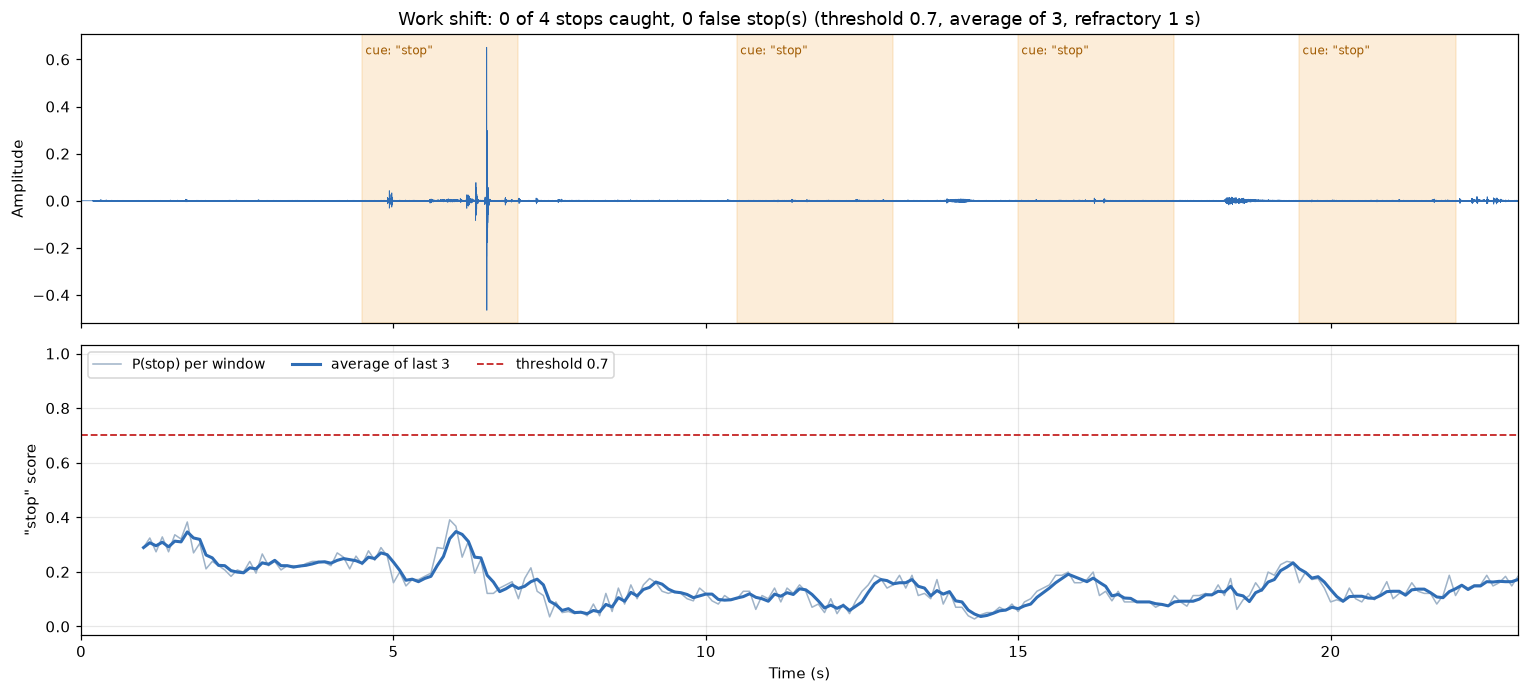

In [21]:
STOP_CUES = [c[0] for c in SHIFT_SCRIPT if c[2]]


def score_against_cues(detections, cues=STOP_CUES, match=STOP_MATCH_SECONDS):
    matched, false_stops, used = [], [], set()
    for d in detections:
        hit = [c for c in cues if c <= d <= c + match and c not in used]
        if hit:
            used.add(hit[0])
            matched.append((hit[0], d))
        else:
            false_stops.append(d)
    misses = [c for c in cues if c not in used]
    return matched, false_stops, misses


shift_result = analyze_clip(shift_audio)
matched, false_stops, misses = score_against_cues(shift_result["detections"])

for d in shift_result["detections"]:
    print(f"🛑 BELT STOPPED at {d:5.1f} s")
print()
for cue, d in matched:
    print(f'"stop" cue at {cue:4.1f} s -> detected at {d:4.1f} s (delay {d - cue:.1f} s after the cue appeared)')
print(f"\nStops said: {len(STOP_CUES)} | correct stops: {len(matched)} | missed: {len(misses)} | false stops: {len(false_stops)}")

plot_stream(shift_audio, shift_result,
            f"Work shift: {len(matched)} of {len(STOP_CUES)} stops caught, {len(false_stops)} false stop(s) "
            f"(threshold {THRESHOLD}, average of {SMOOTH_N}, refractory {REFRACTORY_SECONDS:.0f} s)",
            OUT_DIR / "streaming_work_shift.png", cues=SHIFT_SCRIPT)

### 5.3 🎤 YOU SPEAK: live always-listening mode (60 seconds)

Now the detector runs on the live microphone, exactly as it would on the machine: the microphone delivers 100 ms of audio at a time, a rolling 1 s window is scored every 100 ms, the last 3 scores are averaged, and "🛑 BELT STOPPED" appears when the average reaches 0.7. Talk normally, say other words and say "stop" whenever you like. The message stays on screen for 2 s; the detector is ready again once the 1 s refractory period has passed and the score has dropped below the threshold. To end early, press the stop (interrupt) button of the notebook.

Stops detected at: [50.0, 53.2, 58.6] s


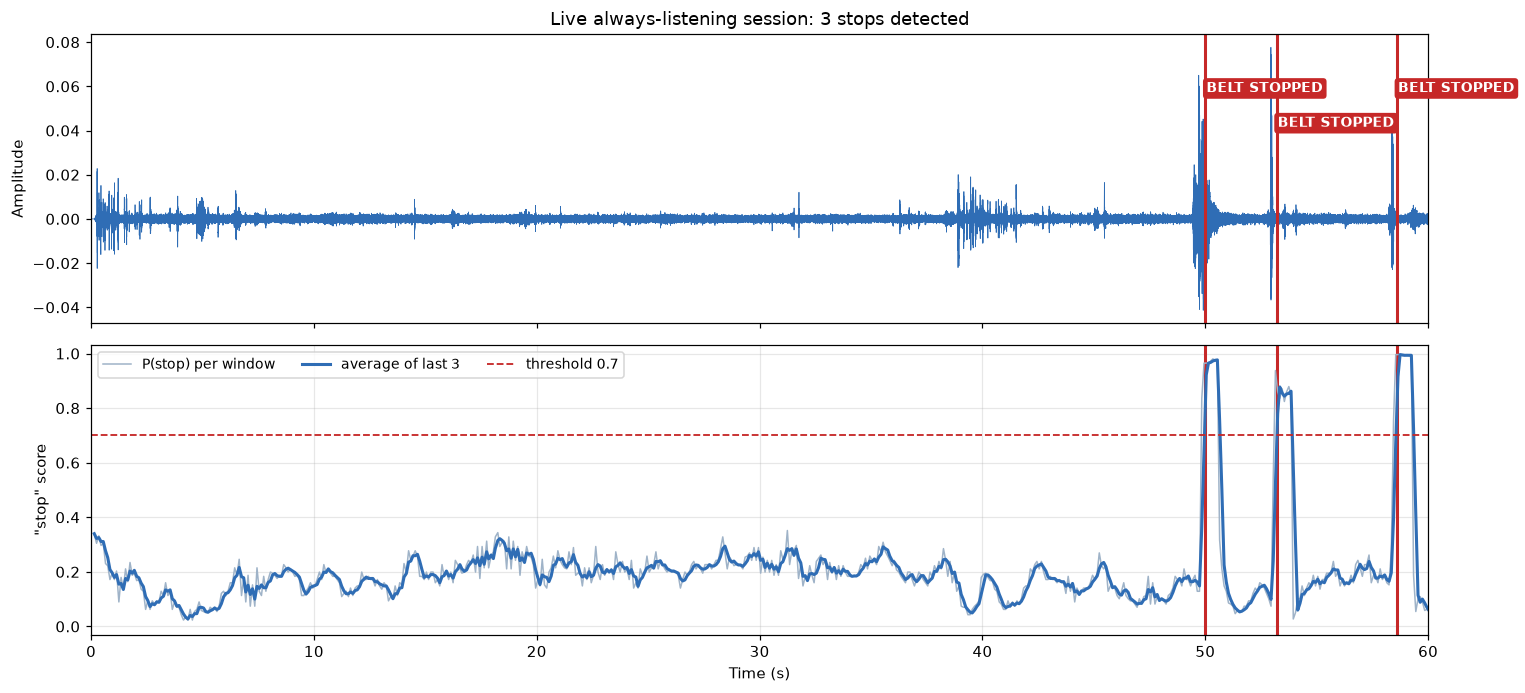

In [22]:
LISTEN_SECONDS = 60
DISPLAY_HOLD_SECONDS = 2.0

audio_q = queue.Queue()


def mic_callback(indata, frames, time_info, status):
    audio_q.put(indata[:, 0].copy())


window_raw = np.zeros(MIC_RATE, dtype=np.float32)
recent = deque(maxlen=SMOOTH_N)
log_t, log_p, log_s, live_detections, recorded = [], [], [], [], []
last_stop, show_until, armed = -np.inf, 0.0, True
view = display(card("#2e7d32", "Belt running", "listening..."), display_id=True)

try:
    with sd.InputStream(device=MIC_DEVICE, channels=1, samplerate=MIC_RATE, dtype="float32",
                        blocksize=int(MIC_RATE * HOP_SECONDS), callback=mic_callback):
        start_time = time.time()
        while time.time() - start_time < LISTEN_SECONDS:
            block = audio_q.get()
            recorded.append(block)
            window_raw = np.concatenate([window_raw[len(block):], block])[-MIC_RATE:]
            window = fix_length(to_model_rate(window_raw))
            p = float(run_model(mfcc_batch(window[np.newaxis])[0])[STOP_ID])
            recent.append(p)
            s = float(np.mean(recent))
            t = time.time() - start_time
            log_t.append(t)
            log_p.append(p)
            log_s.append(s)
            if s < THRESHOLD:
                armed = True
            elif armed and t - last_stop >= REFRACTORY_SECONDS:
                armed = False
                last_stop = t
                live_detections.append(round(t, 1))
                show_until = t + DISPLAY_HOLD_SECONDS
            if t < show_until:
                view.update(card("#c62828", "🛑 BELT STOPPED", f"stop heard at {live_detections[-1]} s | "
                                                               f"stops so far: {len(live_detections)}"))
            else:
                view.update(card("#2e7d32", "Belt running", f"stop score {s:.2f} (threshold {THRESHOLD}) | "
                                                            f"{t:4.1f} s of {LISTEN_SECONDS} s"))
except KeyboardInterrupt:
    pass

view.update(card("#52606d", "Listening ended", f"stops detected: {len(live_detections)}"))
listen_audio = to_model_rate(np.concatenate(recorded)) if recorded else np.zeros(SR, dtype=np.float32)
save_wav16(REC_DIR / "live_listening.wav", listen_audio)
print(f"Stops detected at: {live_detections} s")

listen_result = {"times": np.array(log_t), "probs": np.zeros((len(log_p), len(LABELS))),
                 "smoothed": np.array(log_s), "detections": live_detections}
listen_result["probs"][:, STOP_ID] = log_p
plot_stream(listen_audio, listen_result, f"Live always-listening session: {len(live_detections)} stops detected",
            OUT_DIR / "streaming_live_session.png")

## 6. Safety vs. production (threshold tuning)

The detector is run again with thresholds **0.5, 0.7 and 0.9** (everything else unchanged) on three sets of recordings: the work shift (4 stops), the close-up live trial (10 stops, 10 other words) and the phone clips. The model scores are computed once; only the threshold changes.

- **Miss:** a "stop" that does not stop the belt. Dangerous.
- **False stop:** a stop when no "stop" was said (another word, noise, or a second stop for one shout). Costly.

"stop" words in these recordings: 14


,work shift: misses,work shift: false stops,live trial: misses,live trial: false stops,phone clips: misses,phone clips: false stops,TOTAL misses,TOTAL false stops
threshold,,,,,,,,
0.5,4,0,10,0,0,0,14,0
0.7,4,0,10,0,0,0,14,0
0.9,4,0,10,0,0,0,14,0


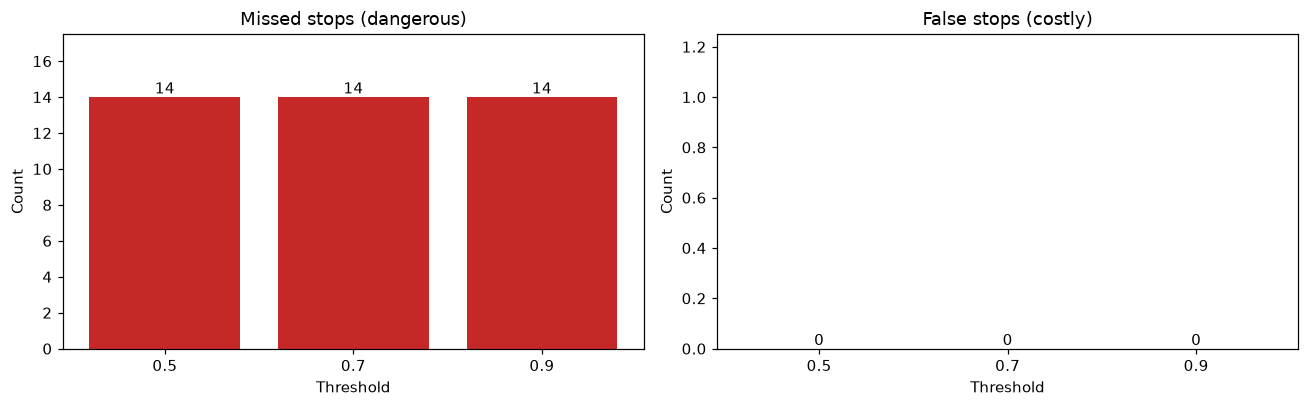

In [23]:
def count_clip_set(clips, threshold):
    misses = false_stops = 0
    for c in clips:
        _, dets = detect_stops(c["times"], c["probs"][:, STOP_ID], threshold)
        if c["expected"] == "stop":
            misses += int(len(dets) == 0)
            false_stops += max(0, len(dets) - 1)
        else:
            false_stops += len(dets)
    return misses, false_stops


rows = []
for th in THRESHOLDS_TO_COMPARE:
    _, shift_dets = detect_stops(shift_result["times"], shift_result["probs"][:, STOP_ID], th)
    m_shift = score_against_cues(shift_dets)
    live_m, live_f = count_clip_set(live_results.get("close", []), th)
    phone_m, phone_f = count_clip_set(list(phone_results.values()), th)
    rows.append({"threshold": th,
                 "work shift: misses": len(m_shift[2]), "work shift: false stops": len(m_shift[1]),
                 "live trial: misses": live_m, "live trial: false stops": live_f,
                 "phone clips: misses": phone_m, "phone clips: false stops": phone_f})
thr_df = pd.DataFrame(rows).set_index("threshold")
thr_df["TOTAL misses"] = thr_df[[c for c in thr_df.columns if "misses" in c]].sum(axis=1)
thr_df["TOTAL false stops"] = thr_df[[c for c in thr_df.columns if "false" in c and "TOTAL" not in c]].sum(axis=1)
thr_df.to_csv(OUT_DIR / "threshold_comparison.csv")
n_stops = len(STOP_CUES) + sum(c["expected"] == "stop" for c in live_results.get("close", [])) \
    + sum(c["expected"] == "stop" for c in phone_results.values())
print(f'"stop" words in these recordings: {n_stops}')
display(thr_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, color, title in [(axes[0], "TOTAL misses", "#c62828", "Missed stops (dangerous)"),
                              (axes[1], "TOTAL false stops", "#2f6db5", "False stops (costly)")]:
    bars = ax.bar([str(t) for t in thr_df.index], thr_df[col], color=color)
    ax.bar_label(bars)
    ax.set(title=title, xlabel="Threshold", ylabel="Count")
    ax.set_ylim(0, max(1, thr_df[col].max()) * 1.25)
plt.tight_layout()
plt.savefig(OUT_DIR / "threshold_comparison.png", bbox_inches="tight")
plt.show()

In [24]:
fewest_misses = thr_df["TOTAL misses"].min()
safe = thr_df[thr_df["TOTAL misses"] == fewest_misses]
RECOMMENDED = float(safe.index.max())
rec_row = thr_df.loc[RECOMMENDED]
print(f"Recommended threshold: {RECOMMENDED}")
print(f"  misses: {int(rec_row['TOTAL misses'])} of {n_stops} stops | false stops: {int(rec_row['TOTAL false stops'])}")
if fewest_misses == 0:
    print("  Reason: it is the highest threshold that still catches every \"stop\" in these recordings,")
    print("  so it keeps the safety officer's zero-miss rule with the fewest false stops for production.")
else:
    print(f"  Reason: no threshold reached zero misses here; {RECOMMENDED} has the fewest misses ({fewest_misses}),")
    print("  and among those it has the fewest false stops. Misses must be fixed first (see section 8).")

Recommended threshold: 0.9
  misses: 14 of 14 stops | false stops: 0
  Reason: no threshold reached zero misses here; 0.9 has the fewest misses (14),
  and among those it has the fewest false stops. Misses must be fixed first (see section 8).


**How to choose.** A lower threshold stops the belt more easily: fewer misses, more false stops. A higher threshold is stricter: fewer false stops, but a quiet or unclear "stop" may be missed. For a safety stop the two errors are not equal: a miss can cost a finger, a false stop costs a few seconds of production. So the rule used above is **safety first**: keep the threshold low enough that no "stop" is missed, and among those choose the highest one so false stops stay as low as possible. False stops can then be reduced further in other ways (averaging more windows, the refractory period, a better microphone position), without risking misses. The red emergency button stays as the backup in all cases.

## 7. Will it fit the chip? (performance)

- **Model size:** the size of `kws_int8.tflite` on disk.
- **Inference time per window:** the average time for one call of the model on one MFCC window, over 1,000 calls (after 50 warm-up calls). It is measured twice: with XNNPACK (the default fast library on laptops) and with the plain reference kernels, which are closer to how a microcontroller library runs.
- **MFCC time:** the average time to turn 1 s of audio into the 49 × 10 MFCC, over 200 runs.

The detector updates every 100 ms, so MFCC + inference must take well under 100 ms. The times below are for this Mac's CPU; a microcontroller is much slower, so these numbers show the work per window, not the final speed on the chip.

In [30]:
def time_ms(fn, runs, warmup):
    for _ in range(warmup):
        fn()
    start = time.perf_counter()
    for _ in range(runs):
        fn()
    return (time.perf_counter() - start) / runs * 1000


q_input = np.random.default_rng(SEED).integers(-128, 128, size=IN["shape"]).astype(np.int8)


def invoke_fast():
    interpreter.set_tensor(IN["index"], q_input)
    interpreter.invoke()


plain_in = plain.get_input_details()[0]


def invoke_plain():
    plain.set_tensor(plain_in["index"], q_input)
    plain.invoke()


one_second = fix_length(load_wav16(bench.path.iloc[0]))[np.newaxis]
infer_fast_ms = time_ms(invoke_fast, 1000, 50)
infer_plain_ms = time_ms(invoke_plain, 1000, 50)
mfcc_ms = time_ms(lambda: mfcc_batch(one_second), 200, 10)
total_ms = mfcc_ms + infer_fast_ms

perf_df = pd.DataFrame({"value": [
    f"{MODEL_KB:.1f} KB (limit 100 KB)",
    f"{infer_fast_ms:.3f} ms",
    f"{infer_plain_ms:.3f} ms",
    f"{mfcc_ms:.2f} ms",
    f"{total_ms:.2f} ms of the {HOP_SECONDS * 1000:.0f} ms budget ({total_ms / (HOP_SECONDS * 1000) * 100:.1f}%)",
]}, index=["int8 model size", "inference per window (XNNPACK)", "inference per window (reference kernels)",
           "MFCC for 1 s of audio", "total per 100 ms update"])
perf_df.to_csv(OUT_DIR / "performance.csv")
display(perf_df)

,value
int8 model size,45.5 KB (limit 100 KB)
inference per window (XNNPACK),0.050 ms
inference per window (reference kernels),0.117 ms
MFCC for 1 s of audio,4.14 ms
total per 100 ms update,4.19 ms of the 100 ms budget (4.2%)


## 8. Real factory conditions (robustness)

### 8.1 🎤 YOU SPEAK: live trial from 1 m away

Move about **1 metre** away from the laptop (an arm's length plus a step) and speak at a normal loud voice, as a worker would across the machine. The prompts are shown in a larger font so they can be read from there. Same 20 prompts in a new random order, about 2 minutes.

In [31]:
live_far_df = run_live_trial("1m", size=72)
display(live_far_df)
far_summary = live_summary(live_far_df)
display(pd.DataFrame({"count": far_summary}).T.rename(index={"count": "1 m away"}))

,word said,system did,outcome,peak stop score,loudest 1 s: prediction,confidence
prompt,,,,,,
1,stop,🛑 BELT STOPPED,correct stop,0.996,stop,0.797
2,down,ignored,correctly ignored,0.224,_unknown_,0.996
3,stop,🛑 BELT STOPPED,correct stop,0.970,stop,0.961
4,stop,🛑 BELT STOPPED,correct stop,0.996,stop,0.996
5,top,ignored,correctly ignored,0.585,_unknown_,0.648
6,no,ignored,correctly ignored,0.217,_unknown_,0.996
7,yes,ignored,correctly ignored,0.368,_unknown_,0.992
8,hello,ignored,correctly ignored,0.220,_unknown_,0.996
9,up,ignored,correctly ignored,0.227,_unknown_,0.934


,correct stop,missed stop,false stop,correctly ignored,accuracy (%)
1 m away,10.0,0.0,1.0,9.0,95.0


### 8.2 🎤 YOU SPEAK: live trial with machine noise

The laptop speaker plays factory noise (a 50 Hz motor hum, low rumble and roller clicks) during the whole trial. Set the Mac volume to about 60%, sit close to the laptop again and say each word once. A fan or a machine-noise video on another device can be added to make it harder. About 2 minutes.

In [33]:
live_noise_df = run_live_trial("noise", with_noise=True)
display(live_noise_df)
noise_summary = live_summary(live_noise_df)
display(pd.DataFrame({"count": noise_summary}).T.rename(index={"count": "with machine noise"}))

,word said,system did,outcome,peak stop score,loudest 1 s: prediction,confidence
prompt,,,,,,
1,stop,🛑 BELT STOPPED,correct stop,0.964,stop,0.941
2,go,ignored,correctly ignored,0.108,_unknown_,0.973
3,stop,ignored,missed stop,0.160,_unknown_,0.980
4,no,ignored,correctly ignored,0.184,_unknown_,0.988
5,down,ignored,correctly ignored,0.113,_unknown_,0.930
6,stop,🛑 BELT STOPPED,correct stop,0.754,stop,0.836
7,stop,🛑 BELT STOPPED,correct stop,0.924,_unknown_,0.703
8,shop,ignored,correctly ignored,0.111,_unknown_,0.996
9,up,ignored,correctly ignored,0.116,_unknown_,0.996


,correct stop,missed stop,false stop,correctly ignored,accuracy (%)
with machine noise,9.0,1.0,1.0,9.0,90.0


### 8.3 Comparison with Lab 5

,clips,accuracy (%),misses,false stops
test,,,,
Lab 5 test set (clean dataset clips),321,98.8,4,0
Bench test (15 dataset clips),15,100.0,0,0
"Live, close (about 30 cm)",20,50.0,10,0
"Live, 1 m away",20,95.0,0,1
"Live, with machine noise",20,90.0,1,1


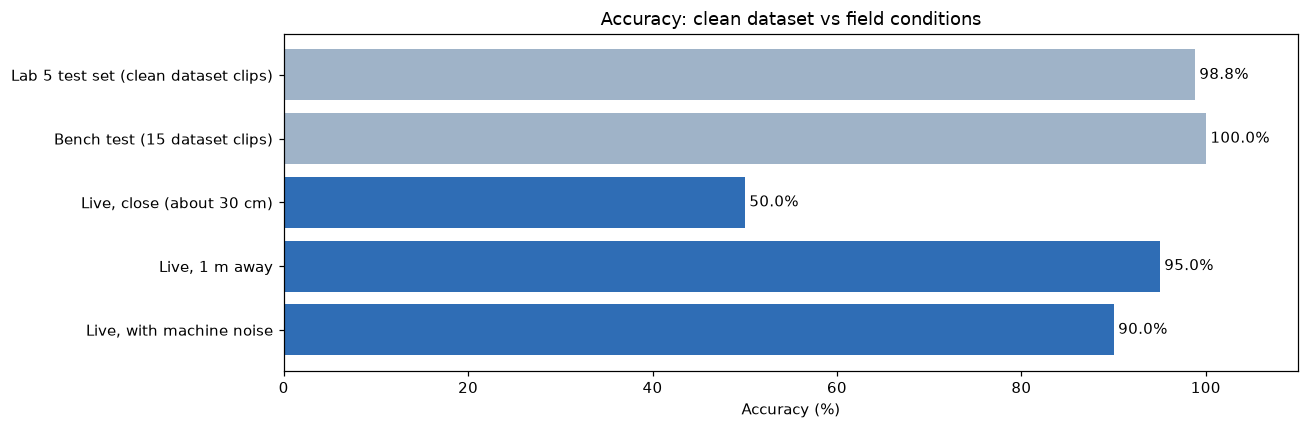

In [34]:
lab5_acc = cfg["test_results_unseen_speakers"]["int8_accuracy"] * 100
robust_rows = [
    {"test": "Lab 5 test set (clean dataset clips)", "clips": cfg["test_results_unseen_speakers"]["test_clips"],
     "accuracy (%)": round(lab5_acc, 1),
     "misses": cfg["test_results_unseen_speakers"]["int8_misses"],
     "false stops": cfg["test_results_unseen_speakers"]["int8_false_alarms"]},
    {"test": "Bench test (15 dataset clips)", "clips": len(bench_df),
     "accuracy (%)": round(bench_correct / len(bench_df) * 100, 1),
     "misses": int(((bench_df["true class"] == "stop") & (bench_df.prediction != "stop")).sum()),
     "false stops": int(((bench_df["true class"] != "stop") & (bench_df.prediction == "stop")).sum())},
]
if len(phone_df):
    robust_rows.append({"test": "Phone clips", "clips": len(phone_df),
                        "accuracy (%)": round((phone_df.correct == "yes").mean() * 100, 1),
                        "misses": int(((phone_df.should == "stop the belt") & (phone_df.correct == "NO")).sum()),
                        "false stops": int(((phone_df.should == "ignore") & (phone_df.correct == "NO")).sum())})
for name, summ in [("Live, close (about 30 cm)", close_summary), ("Live, 1 m away", far_summary),
                   ("Live, with machine noise", noise_summary)]:
    robust_rows.append({"test": name, "clips": 20, "accuracy (%)": summ["accuracy (%)"],
                        "misses": summ["missed stop"], "false stops": summ["false stop"]})
robust_df = pd.DataFrame(robust_rows).set_index("test")
robust_df.to_csv(OUT_DIR / "robustness.csv")
display(robust_df)

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["#9fb3c8"] * 2 + ["#2f6db5"] * (len(robust_df) - 2)
bars = ax.barh(robust_df.index[::-1], robust_df["accuracy (%)"][::-1], color=colors[::-1])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(xlabel="Accuracy (%)", xlim=(0, 110), title="Accuracy: clean dataset vs field conditions")
plt.tight_layout()
plt.savefig(OUT_DIR / "robustness.png", bbox_inches="tight")
plt.show()

**Explanation for the manager: why the field results differ from Lab 5**

The Lab 5 number was measured on clean, close-up dataset recordings. The field trial changes four things at once:

1. **A different microphone.** The model learned from thousands of phones and laptops in the dataset, but not from this MacBook microphone or the phone used here. Every microphone colors the sound a little differently, so the MFCC numbers shift slightly.
2. **Distance.** From 1 m away the voice is quieter, and more of the room's echo reaches the microphone. The "s" hiss at the start of "stop", which the model relies on, is weak and high-pitched, so it fades first.
3. **Machine noise.** Noise lowers the signal-to-noise ratio. The model was trained with factory-style noise, which helps, but the real noise comes out of a laptop speaker, which sounds different from the noise used in training.
4. **New voices and new words.** "Top" and "shop" were never in the training data (the \_unknown\_ class only had 7 command words), and they share sounds with "stop", so they are the most likely false stops.

**What would close the gap before installation:** record "stop" and normal talk from the real workers at the real machine and add them to training; add echo (reverberation) and louder noise to the augmentation; add "top", "shop" and other common factory words to \_unknown\_; mount the microphone close to where workers stand; and keep the red emergency button as the backup.

## 9. Summary

In [35]:
summary = pd.DataFrame([
    ["Model details", "input 1 x 49 x 10 x 1 int8, 3 outputs",
     f"input {[int(v) for v in IN['shape']]} {IN['dtype'].__name__}, output {[int(v) for v in OUT['shape']]} {OUT['dtype'].__name__}"],
    ["Bench test", "about 13 to 15 of 15", f"{bench_correct} of {len(bench_df)}"],
    ["Phone clips", "report each clip",
     f"{(phone_df.correct == 'yes').sum()} of {len(phone_df)} correct" if len(phone_df) else "no clips added"],
    ["Live trial (close)", "most stops caught",
     f"{close_summary['correct stop']}/10 stops caught, {close_summary['false stop']} false stops"],
    ["Work shift (streaming)", "each stop detected once",
     f"{len(matched)}/{len(STOP_CUES)} caught, {len(false_stops)} false, {len(misses)} missed"],
    ["Recommended threshold", "about 0.5 to 0.7", f"{RECOMMENDED}"],
    ["Model size", "about 45 to 50 KB", f"{MODEL_KB:.1f} KB"],
    ["Inference per window", "under 1 ms", f"{infer_fast_ms:.3f} ms"],
    ["MFCC for 1 s", "report", f"{mfcc_ms:.2f} ms"],
    ["Live trial 1 m / noise", "a little lower than Lab 5",
     f"{far_summary['accuracy (%)']}% / {noise_summary['accuracy (%)']}% vs Lab 5 {lab5_acc:.1f}%"],
], columns=["item", "lab expects", "this notebook"]).set_index("item")
summary.to_csv(OUT_DIR / "summary.csv")
display(summary)

print("Saved in", LAB6_DIR)
for folder in [OUT_DIR, REC_DIR]:
    files = sorted(p for p in folder.iterdir() if p.is_file())
    print(f"  {folder.name}/: {len(files)} files")

,lab expects,this notebook
item,,
Model details,"input 1 x 49 x 10 x 1 int8, 3 outputs","input [1, 49, 10, 1] int8, output [1, 3] int8"
Bench test,about 13 to 15 of 15,15 of 15
Phone clips,report each clip,no clips added
Live trial (close),most stops caught,"0/10 stops caught, 0 false stops"
Work shift (streaming),each stop detected once,"0/4 caught, 0 false, 4 missed"
Recommended threshold,about 0.5 to 0.7,0.9
Model size,about 45 to 50 KB,45.5 KB
Inference per window,under 1 ms,0.050 ms
MFCC for 1 s,report,4.14 ms


Saved in /Users/Tanmay/Downloads/Lab6_KWS
  outputs/: 12 files
  recordings/: 62 files
